# Random Forest

for a secondary type of model create a random forest [exlpain why this model specifically]

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

In [4]:
# load the cleaned Taiwan data made by 01-Introduction
ROOT = Path.cwd().parent
taiwan = pd.read_csv(ROOT / "data" / "processed" / "taiwan-clean.csv", index_col="ID")

In [6]:
#order data chronologically by month (PAY_1 is the most recent month, PAY_6 is the oldest)
months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
pay_cols  = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_1"]
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

# create table which shows the relevant data from the cleaned dataframe for a given client (row)
def client_table(taiwan, n=0):
    r = taiwan.iloc[n]
    return pd.DataFrame(
        [list(range(1, 8)),
         list(r[pay_cols]) + [r["default payment next month"]],
         list(r[bill_cols]) + [r["default payment next month"]],
         list(r[amt_cols]) + [r["default payment next month"]]],
        index=["Month no.", "Status (PAY / default label)", "BILL_AMT", "PAY_AMT"],
        columns=months,
    )

print(client_table(taiwan, 1))

                               Apr   May   Jun   Jul   Aug   Sep  Oct
Month no.                        1     2     3     4     5     6    7
Status (PAY / default label)     2     0     0     0     2    -1    1
BILL_AMT                      3261  3455  3272  2682  1725  2682    1
PAY_AMT                       2000     0  1000  1000  1000     0    1


AUC 0.776 | Brier 0.136 | BSS 0.210
Acc 0.696 | recall 0.704 | precision 0.395
[[4865 2143]
 [ 590 1401]]


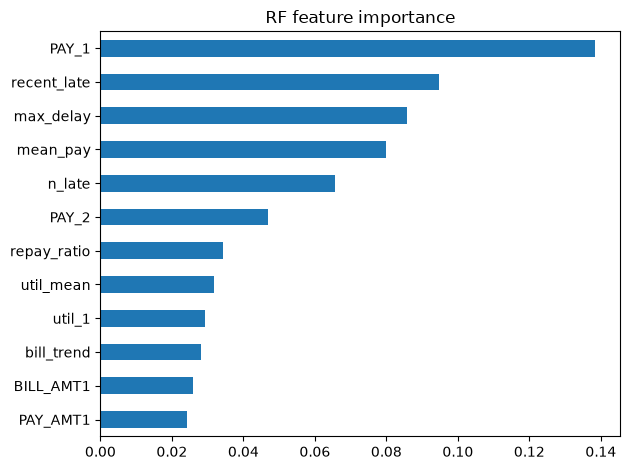

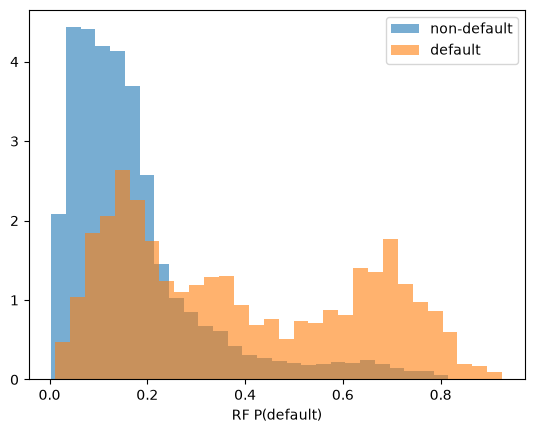

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, confusion_matrix,
                             brier_score_loss, recall_score, precision_score, roc_curve)

TARGET = "default payment next month"
X = taiwan.drop(columns=TARGET).copy()
y = taiwan[TARGET]

# --- feature engineering (chronological columns from your earlier cell) ---
X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)          # months overdue
X["max_delay"]   = X[pay_cols].max(axis=1)
X["mean_pay"]    = X[pay_cols].mean(axis=1)
X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
X["util_1"]      = X["BILL_AMT1"] / X["LIMIT_BAL"]         # credit utilisation
X["util_mean"]   = X[bill_cols].mean(axis=1) / X["LIMIT_BAL"]
X["bill_trend"]  = (X["BILL_AMT1"] - X["BILL_AMT6"]) / X["LIMIT_BAL"]
X["repay_ratio"] = X[amt_cols].sum(axis=1) / (X[bill_cols].clip(lower=0).sum(axis=1) + 1)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                            max_features="sqrt", n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr)
p_rf = rf.predict_proba(Xte)[:, 1]

# threshold chosen on TRAIN data (Youden's J)
f, t, th = roc_curve(ytr, rf.predict_proba(Xtr)[:, 1])
thr = th[np.argmax(t - f)]
pred = (p_rf > thr).astype(int)

base = brier_score_loss(yte, np.full(len(yte), ytr.mean()))
bs = brier_score_loss(yte, p_rf)
print(f"AUC {roc_auc_score(yte, p_rf):.3f} | Brier {bs:.3f} | BSS {1 - bs/base:.3f}")
print(f"Acc {accuracy_score(yte, pred):.3f} | recall {recall_score(yte, pred):.3f} "
      f"| precision {precision_score(yte, pred):.3f}")
print(confusion_matrix(yte, pred))

imp = pd.Series(rf.feature_importances_, Xtr.columns).sort_values()
imp.tail(12).plot.barh(title="RF feature importance"); plt.tight_layout(); plt.show()

plt.hist(p_rf[yte == 0], bins=30, alpha=.6, density=True, label="non-default")
plt.hist(p_rf[yte == 1], bins=30, alpha=.6, density=True, label="default")
plt.xlabel("RF P(default)"); plt.legend(); plt.show()

hump of defaulters as non defaulters, data lines up, sudden defaults, since PAY_1 is the highest predictor in the model if someone goes from <0 to default they are unlikely to be caught. smoothing likely causes some of the issues. add features which could help the model. the model even though it is not perfect at predicting has useful information. the features of the high probability defaulters can be analysed. Include an attempt at feature engeneering.